# Retrievals: Using the Model Functions

Written by [Evert Nasedkin](mailto:nasedkinevert@gmail.com?subject=[petitRADTRANS]%20Retrievals).

Please cite pRT's retrieval package [(Nasedkin et al. 2024)](https://ui.adsabs.harvard.edu/abs/2024JOSS....9.5875N/abstract) in addition to pRT [(Mollière et al. 2019)](https://ui.adsabs.harvard.edu/abs/2019A%26A...627A..67M/abstract) if you make use of the retrieval package for your work.

This notebook is the update to the [legacy models tutorial](./retrieval_models.ipynb). It shows how to call the new model function interface directly — outside of a full retrieval loop — to compute spectra and temperature profiles.

The new interface differs from the legacy one in two key ways:

- The first argument is a `ModelContext` (containing the `Radtrans` object and evaluation flags) instead of the bare `Radtrans` object.
- The second argument is a `PhysicalParams` mapping (values accessed directly with `params['key']`) instead of a `dict` of `Parameter` objects (accessed with `params['key'].value`).

This interface is required when using the JAXNS sampler, and is also the recommended path for new custom models because it is fully JAX-traceable.

As with `retrieval_models.ipynb`, the cells below calculate models in isolation. In a real retrieval you would register the same function via `add_data(..., model_generating_function=...)` and the `RetrievalConfig` / `Retrieval` machinery handles everything else.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import petitRADTRANS as prt
from petitRADTRANS import physical_constants as cst
from petitRADTRANS.plotlib.style import set_petitradtrans_plot_style
from petitRADTRANS.retrieval.runtime import ModelContext, PhysicalParams

set_petitradtrans_plot_style()

print(f"JAX devices: {jax.devices()}")

Using pRT Plotting style!
JAX devices: [CpuDevice(id=0)]


## The `ModelContext` and `PhysicalParams` objects

Every model function has the signature:

```python
def my_model(model_context: ModelContext, physical_params: PhysicalParams, pt_plot_mode: bool = False) -> ModelResult:
    ...
```

- **`ModelContext`** is a frozen dataclass that carries the `Radtrans` object plus evaluation flags such as `return_contribution`, `adaptive_mesh_refinement`, etc.
- **`PhysicalParams`** is a JAX-pytree-compatible mapping of parameter name → scalar value. Unlike the legacy `Parameter` dict, you access values directly: `physical_params['log_g']` rather than `parameters['log_g'].value`.
- The return value is a **`ModelResult`** with fields `wavelengths`, `spectrum`, `pressures`, `temperatures`, and `auxiliary_outputs`.

Both objects are constructed from plain Python dicts, as shown in the examples below.

## Emission spectrum: `spline_eddington_adiabatic_emission`

We set up a `Radtrans` object and compute a disequilibrium-chemistry emission spectrum for an HR 8799-like planet using the Mollière 2020 temperature profile.

The same set-up can be used for any of the runtime-native emission functions; just swap the function name and adjust the parameter dictionary accordingly.

In [2]:
from petitRADTRANS.retrieval.models import (
    spline_eddington_adiabatic_emission,
    guillot_emission,
    guillot_emission_add_gaussian_temperature,
    gradient_profile_emission,
    interpolated_profile_emission,
    guillot_transmission,
    isothermal_transmission
)

In [ ]:
line_species = (
    'H2O__POKAZATEL.R300',
    'CO-NatAbund.R300',
    'CH4.R300',
    'CO2.R300',
    'H2S.R300',
    'NH3.R300',
)

rayleigh_species = ('H2', 'He')
continuum_opacities = ('H2--H2', 'H2--He')
pressures = jnp.logspace(-6, 2, 100)

atmosphere_emission = prt.radtrans.Radtrans(
    pressures=pressures,
    line_species=line_species,
    rayleigh_species=rayleigh_species,
    gas_continuum_contributors=continuum_opacities,
    cloud_species=(),
    wavelength_boundaries=(1, 5),
)

Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R300_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CH4.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__YT34to10.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO2.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__UCL-4000.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'H2S.R300' from file 

### Building `ModelContext` and `PhysicalParams`

`ModelContext` accepts `return_contribution=True` to request the emission contribution function as an auxiliary output.

`PhysicalParams.from_mapping()` builds the parameter object from a plain dict. Values are accessed directly (no `.value` attribute).

In [ ]:
# Build the ModelContext — holds the Radtrans object and evaluation flags.
emission_context = ModelContext(
    name='hr8799_emission',
    mode='evaluate',
    radtrans=atmosphere_emission,
    adaptive_mesh_refinement=False,
    return_contribution=False,
)

# Build PhysicalParams from a plain dict.
# Values are plain scalars (or JAX arrays) — no Parameter wrappers needed.
# We use the from_mapping method instead of the standard constructure so
# that we can have arbitrary parameter names for the model functions.
emission_params = PhysicalParams.from_mapping({
    # System
    'distance_to_system': 41.3 * cst.pc,
    # Planet — two of (log_g, planet_radius, mass)
    'mass':          5.0 * cst.m_jup,
    'planet_radius': 1.0 * cst.r_jup_mean,
    # Mollière 2020 temperature profile
    'T_int':      1500.0,
    'T3':            0.8,
    'T2':            0.4,
    'T1':            0.5,
    'log_delta':     0.65,
    'alpha':         1.70,
    # Equilibrium chemistry
    'Fe/H':          1.0,
    'C/O':           0.7,
    'log_pquench':   2.5,
})

### Calling the model

The return value is a `ModelResult`. Use `result.wavelengths` and `result.spectrum` to get the spectrum, and `result.pressures` / `result.temperatures` when `pt_plot_mode=True`.

In [5]:
# Compute the emission spectrum
result = spline_eddington_adiabatic_emission(
    emission_context, emission_params, pt_plot_mode=False
)
wavelengths = result.wavelengths
spectrum = result.spectrum

# Compute the T-P profile
pt_result = spline_eddington_adiabatic_emission(
    emission_context, emission_params, pt_plot_mode=True
)
p_profile = pt_result.pressures
t_profile = pt_result.temperatures

Loading chemical equilibrium chemistry table from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/pre_calculated_chemistry/equilibrium_chemistry/equilibrium_chemistry.chemtable.petitRADTRANS.h5'... Done.


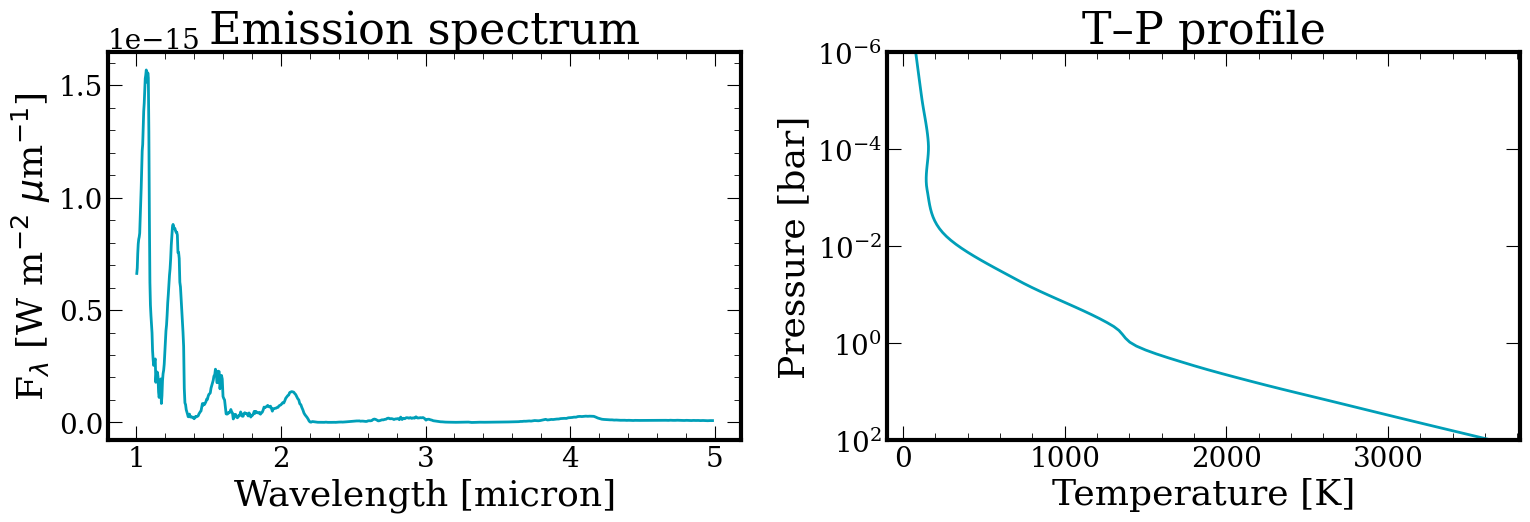

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(wavelengths, spectrum, linewidth=2)
axes[0].set_xlabel('Wavelength [micron]')
axes[0].set_ylabel(r'F$_{\lambda}$ [W m$^{-2}$ $\mu$m$^{-1}$]')
axes[0].set_title('Emission spectrum')

axes[1].plot(t_profile, p_profile, linewidth=2)
axes[1].set_xlabel('Temperature [K]')
axes[1].set_ylabel('Pressure [bar]')
axes[1].set_ylim(1e2, 1e-6)
axes[1].set_yscale('log')
axes[1].set_title('T–P profile')

fig.tight_layout()

## Other emission models

Swapping to a different built-in model requires only two changes: the function name and the parameter dictionary.

### Guillot emission

Replace `T1`/`T2`/`T3`/`log_delta`/`alpha` with `T_equ`, `gamma`, and `log_kappa_IR`.

In [7]:
guillot_context = ModelContext(
    name='guillot_emission_demo',
    mode='evaluate',
    radtrans=atmosphere_emission,
    adaptive_mesh_refinement=False,
)

guillot_params = PhysicalParams.from_mapping({
    'distance_to_system': 41.3 * cst.pc,
    'mass':          5.0 * cst.m_jup,
    'planet_radius': 1.0 * cst.r_jup_mean,
    # Guillot temperature profile
    'T_int':         700.0,
    'T_equ':        1300.0,
    'gamma':          0.4,
    'log_kappa_IR':  -1.5,
    # Equilibrium chemistry
    'Fe/H':  1.0,
    'C/O':   0.7,
    'log_pquench': 2.5,
})

guillot_result = guillot_emission(guillot_context, guillot_params)
print(f'Computed {guillot_result.wavelengths.shape[0]} wavelength points.')

Computed 482 wavelength points.


### Gradient profile (dT/d log P) emission

This model is described in [Zhang et al. (2023)](https://ui.adsabs.harvard.edu/abs/2023AJ....166..198Z/abstract). The parameters are:
- `N_layers`: number of pressure layers.
- `T_bottom`: temperature at the deepest pressure level.
- `PTslope_{i}`: dT/d(log P) for each layer, from deep (i=1) to shallow (i=N_layers).

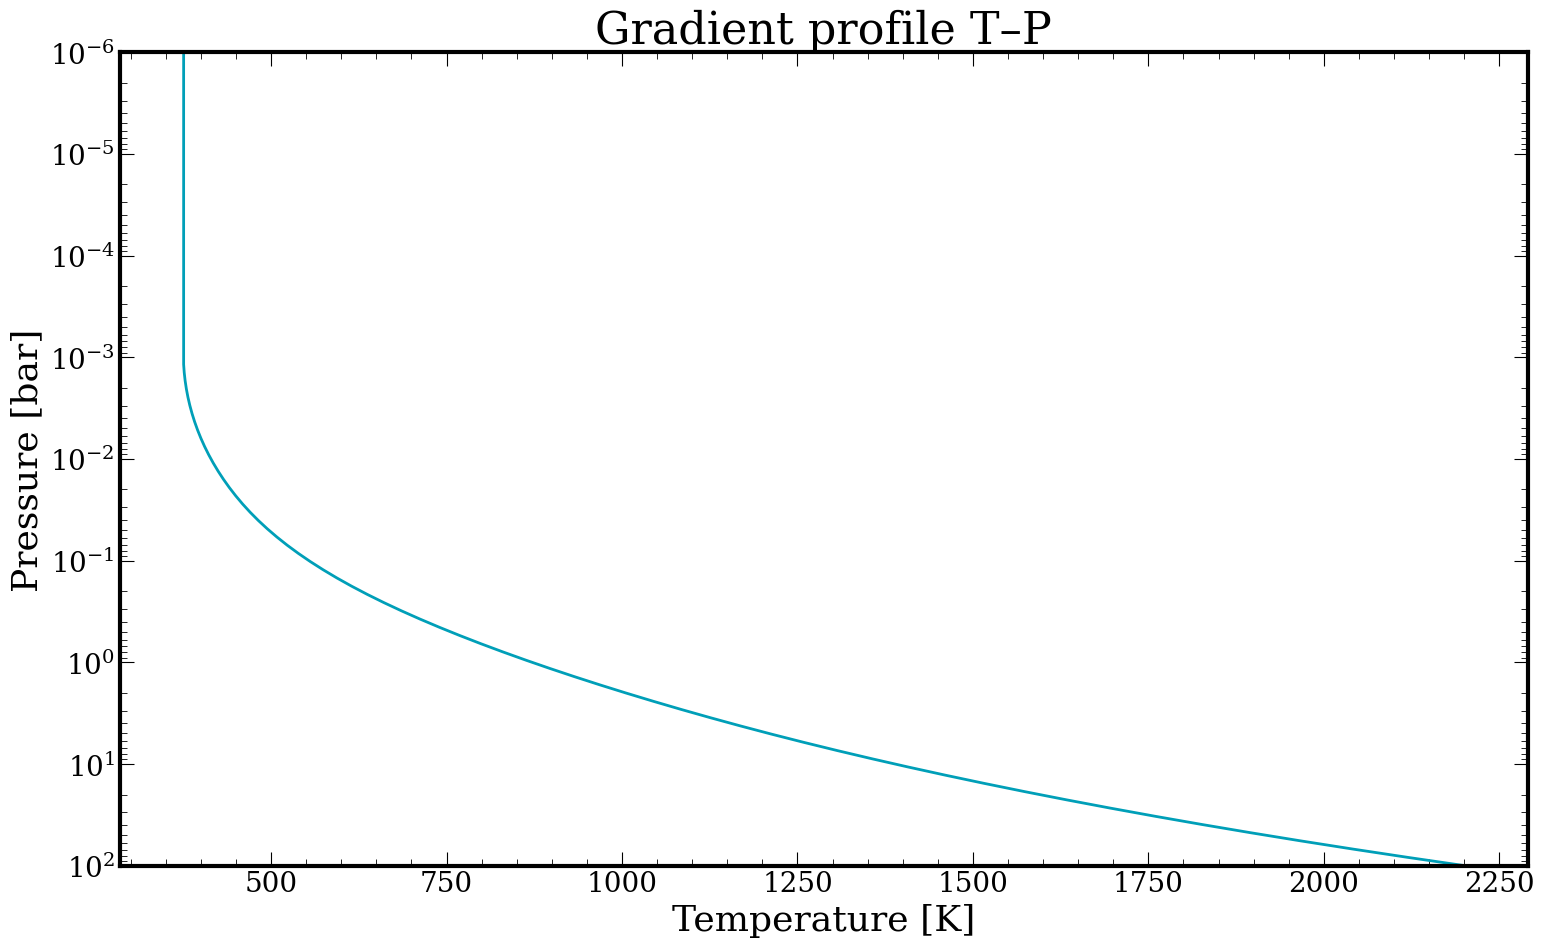

In [8]:
n_layers = 5

gradient_context = ModelContext(
    name='gradient_emission_demo',
    mode='evaluate',
    radtrans=atmosphere_emission,
    adaptive_mesh_refinement=False,
)

gradient_params = PhysicalParams.from_mapping({
    'distance_to_system': 41.3 * cst.pc,
    'mass':          5.0 * cst.m_jup,
    'planet_radius': 1.0 * cst.r_jup_mean,
    # Gradient profile
    'N_layers': n_layers,
    'top_of_atmosphere_pressure': -3,
    'bottom_of_atmosphere_pressure': 2,
    'T_bottom': 2200.0,
    'PTslope_1': 0.2,
    'PTslope_2': 0.2,
    'PTslope_3': 0.2,
    'PTslope_4': 0.1,
    'PTslope_5':  0.0,
    # Equilibrium chemistry
    'Fe/H':  0.5,
    'C/O':   0.55,
    'log_pquench': 1,
})

gradient_pt = gradient_profile_emission(
    gradient_context, gradient_params, pt_plot_mode=True
)

fig, ax = plt.subplots()
ax.plot(gradient_pt.temperatures, gradient_pt.pressures, linewidth=2)
ax.set_xlabel('Temperature [K]')
ax.set_ylabel('Pressure [bar]')
ax.set_ylim(1e2, 1e-6)
ax.set_yscale('log')
ax.set_title('Gradient profile T–P')
fig.tight_layout()

## Transmission spectrum: `guillot_transmission`

For transmission models the required planet/star parameters are slightly different: `stellar_radius` must be provided (used to normalise the transit depth), and `distance_to_system` is not needed. A `reference_pressure` sets the pressure level at which `planet_radius` is defined (default: 100 bar).

We set up a WASP-39b-like planet.

In [9]:
atmosphere_transmission = prt.radtrans.Radtrans(
    pressures=pressures,
    line_species=(
        'H2O__POKAZATEL.R300',
        'CO-NatAbund.R300',
        'CH4.R300',
        'CO2.R300',
    ),
    rayleigh_species=('H2', 'He'),
    gas_continuum_contributors=('H2--H2', 'H2--He'),
    cloud_species=(),
    wavelength_boundaries=(1, 5),
)

Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R300_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CH4.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__YT34to10.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO2.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__UCL-4000.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Successfully loaded all line opacities
 Loading CIA opa

In [10]:
transmission_context = ModelContext(
    name='wasp39_transmission',
    mode='evaluate',
    radtrans=atmosphere_transmission,
    adaptive_mesh_refinement=False,
    return_contribution=False,
)

transmission_params = PhysicalParams.from_mapping({
    # Star
    'stellar_radius': 0.9324 * cst.r_sun,
    # Planet
    'planet_radius':  1.3 * cst.r_jup_mean,
    'log_g':          2.75,
    'reference_pressure': 100.0,
    # Isothermal temperature profile
    'temperature':   750.0,
    # Equilibrium chemistry
    'Fe/H': 1.0,
    'C/O':  0.55,
})

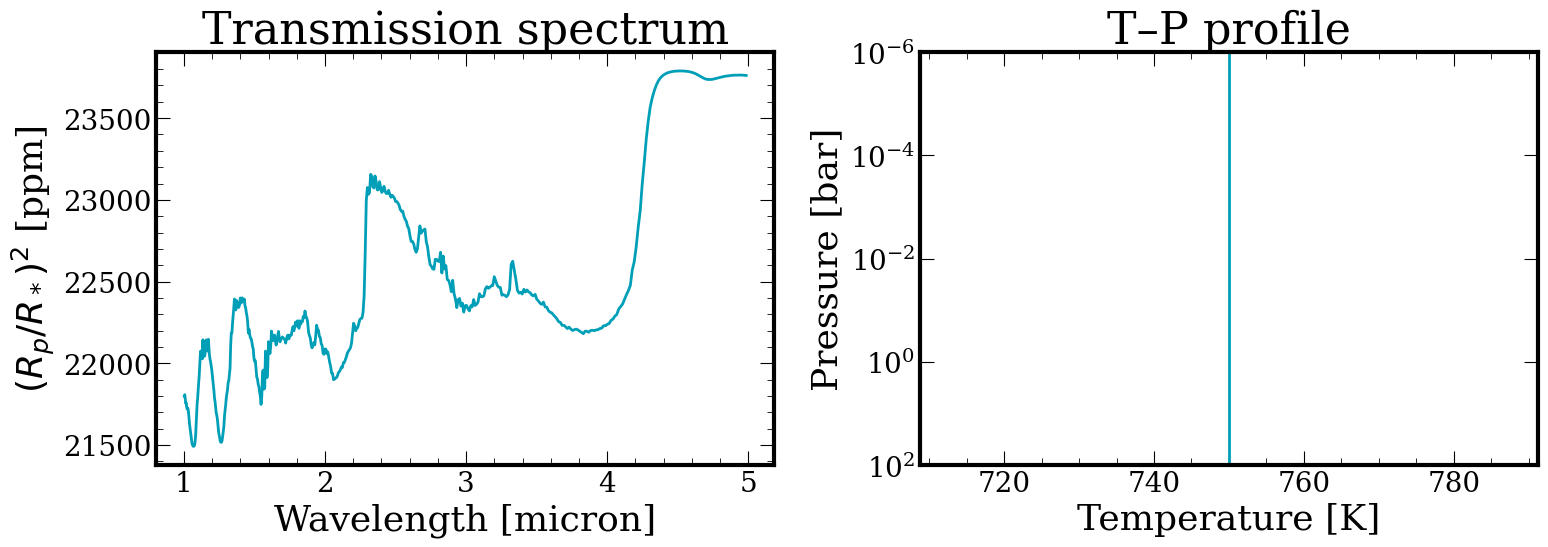

In [11]:
trans_result = isothermal_transmission(
    transmission_context, transmission_params, pt_plot_mode=False
)

trans_pt = isothermal_transmission(
    transmission_context, transmission_params, pt_plot_mode=True
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(trans_result.wavelengths, trans_result.spectrum * 1e6, linewidth=2)
axes[0].set_xlabel('Wavelength [micron]')
axes[0].set_ylabel(r'$(R_p/R_*)^2$ [ppm]')
axes[0].set_title('Transmission spectrum')

axes[1].plot(trans_pt.temperatures, trans_pt.pressures, linewidth=2)
axes[1].set_xlabel('Temperature [K]')
axes[1].set_ylabel('Pressure [bar]')
axes[1].set_ylim(1e2, 1e-6)
axes[1].set_yscale('log')
axes[1].set_title('T–P profile')

fig.tight_layout()

In [12]:
transmission_context = ModelContext(
    name='wasp39_transmission',
    mode='evaluate',
    radtrans=atmosphere_transmission,
    adaptive_mesh_refinement=False,
    return_contribution=False,
)

transmission_params = PhysicalParams.from_mapping({
    # Star
    'stellar_radius': 0.9324 * cst.r_sun,
    # Planet
    'planet_radius':  1.3 * cst.r_jup_mean,
    'log_g':          2.75,
    'reference_pressure': 100.0,
    # Guillot temperature profile
    'T_int':         750.0,
    'T_equ':         600.0,
    'log_kappa_IR':   -1.0,
    'gamma':           1.0,
    # Haze and gray cloud
    'log_Pcloud':      -2.0,
    'power_law_opacity_350nm': 1e-4,
    'power_law_opacity_coefficient': -3,
    # Equilibrium chemistry
    'Fe/H': 1.0,
    'C/O':  0.55,
})

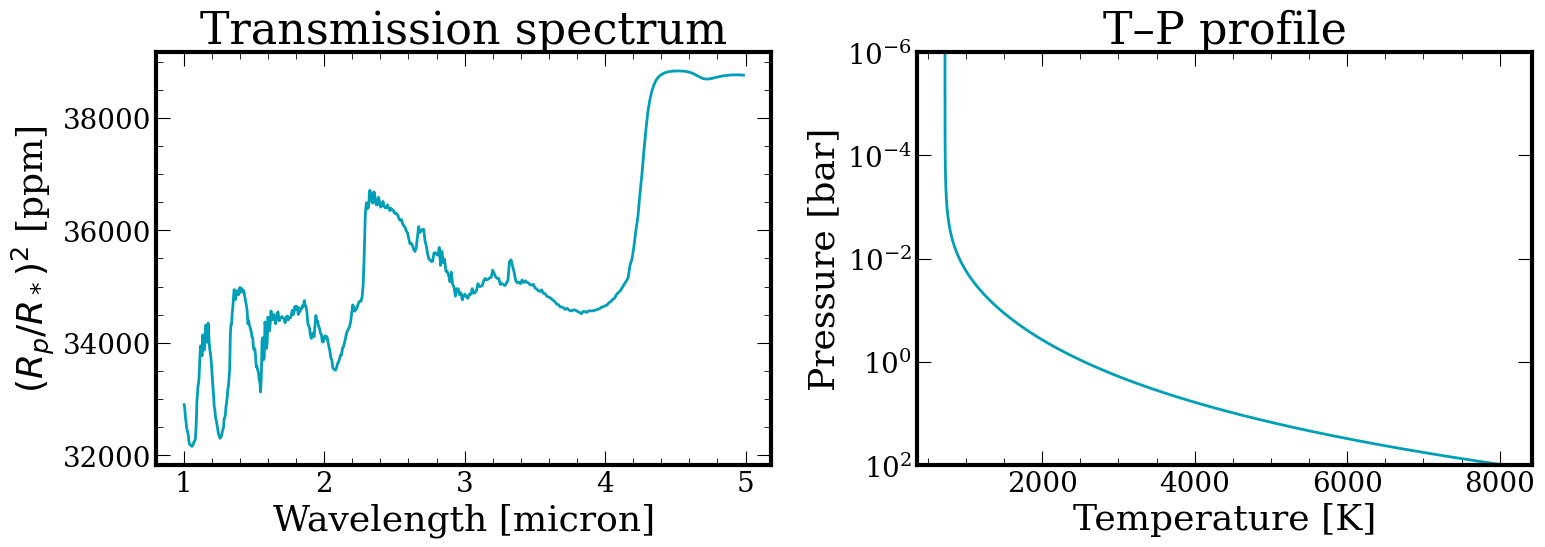

In [13]:
trans_result = guillot_transmission(
    transmission_context, transmission_params, pt_plot_mode=False
)

trans_pt = guillot_transmission(
    transmission_context, transmission_params, pt_plot_mode=True
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(trans_result.wavelengths, trans_result.spectrum * 1e6, linewidth=2)
axes[0].set_xlabel('Wavelength [micron]')
axes[0].set_ylabel(r'$(R_p/R_*)^2$ [ppm]')
axes[0].set_title('Transmission spectrum')

axes[1].plot(trans_pt.temperatures, trans_pt.pressures, linewidth=2)
axes[1].set_xlabel('Temperature [K]')
axes[1].set_ylabel('Pressure [bar]')
axes[1].set_ylim(1e2, 1e-6)
axes[1].set_yscale('log')
axes[1].set_title('T–P profile')

fig.tight_layout()

## Writing a custom model

To write a custom model you only need to accept `(model_context, physical_params, pt_plot_mode=False)` and return a `ModelResult`. For simplicity, we delegate the actual radiative transfer to `calculate_emission_spectrum_runtime` or `calculate_transmission_spectrum_runtime` by constructing a `ModelInputs` container.

The example below adds a free-chemistry isothermal transmission model — the simplest possible case.

In [ ]:
from petitRADTRANS.retrieval.models import (
    calculate_transmission_spectrum_runtime,
)
from petitRADTRANS.retrieval.runtime import ModelInputs, ModelResult


def custom_isothermal_free_chemistry_transmission(
    model_context: ModelContext,
    physical_params: PhysicalParams,
    pt_plot_mode: bool = False,
) -> ModelResult:
    """Isothermal transmission model with one free-chemistry species (H2O).

    Required parameters
    -------------------
    temperature         : isothermal temperature [K]
    log_g               : log10 surface gravity [cm/s^2]
    planet_radius       : planet radius [cm]
    stellar_radius      : stellar radius [cm]
    reference_pressure  : reference pressure for planet_radius [bar]
    log_H2O             : log10 H2O mass fraction
    log_Pcloud          : log10 gray cloud deck pressure [bar]
    """
    p = model_context.radtrans.pressures / 1e6          # bar
    temperatures = jnp.full_like(p, physical_params['temperature'])

    if pt_plot_mode:
        return ModelResult(kind='pt_profile', pressures=p, temperatures=temperatures)

    log_h2o = physical_params['log_H2O']
    x_h2o = jnp.power(10.0, log_h2o)
    remainder = jnp.clip(1.0 - x_h2o, 1e-12, 1.0)

    # Build the mass fraction dict — keys must match line_species names
    abundances = {
        species: jnp.full_like(p, x_h2o)
        if 'H2O' in species or 'POKAZATEL' in species
        else jnp.full_like(p, 0.0)
        for species in model_context.radtrans.line_species
    }
    abundances['H2'] = jnp.full_like(p, 0.74 * remainder)
    abundances['He'] = jnp.full_like(p, 0.26 * remainder)

    model_inputs = ModelInputs(
        pressures=p,
        temperatures=temperatures,
        abundances=abundances,
        mean_molar_masses=jnp.full_like(p, 2.33),
        gravity=jnp.power(10.0, physical_params['log_g']),
        planet_radius=physical_params['planet_radius'],
        stellar_radius=physical_params['stellar_radius'],
        reference_pressure=physical_params['reference_pressure'],
        opaque_cloud_top_pressure=jnp.power(10.0, physical_params['log_Pcloud']),
    )

    return calculate_transmission_spectrum_runtime(model_context, model_inputs)

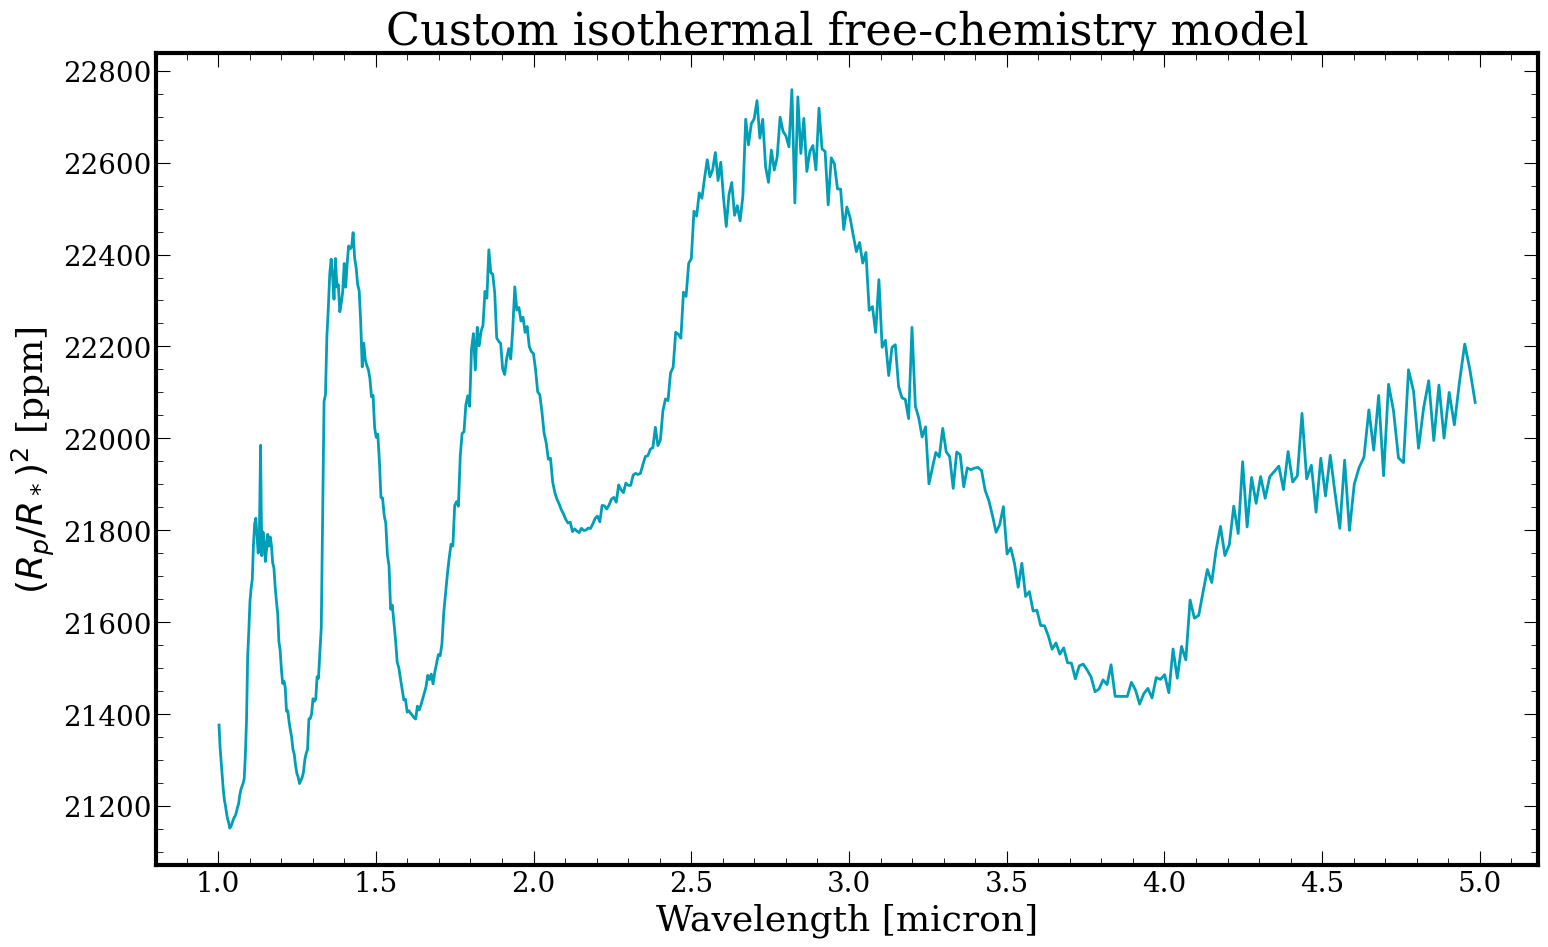

In [15]:
# Reuse the transmission Radtrans object from the previous section
custom_context = ModelContext(
    name='custom_isothermal',
    mode='evaluate',
    radtrans=atmosphere_transmission,
    adaptive_mesh_refinement=False,
)

custom_params = PhysicalParams.from_mapping({
    'temperature':        900.0,
    'log_g':              2.75,
    'planet_radius':      1.3 * cst.r_jup_mean,
    'stellar_radius':     0.9324 * cst.r_sun,
    'reference_pressure': 100.0,
    'log_H2O':            -3.0,
    'log_Pcloud':          0.0,
})

custom_result = custom_isothermal_free_chemistry_transmission(custom_context, custom_params)

fig, ax = plt.subplots()
ax.plot(custom_result.wavelengths, custom_result.spectrum * 1e6, linewidth=2)
ax.set_xlabel('Wavelength [micron]')
ax.set_ylabel(r'$(R_p/R_*)^2$ [ppm]')
ax.set_title('Custom isothermal free-chemistry model')
fig.tight_layout()

## Using the model in a retrieval

Once you have a model function it plugs straight into `RetrievalConfig.add_data` exactly like a legacy model:

```python
from petitRADTRANS.retrieval import RetrievalConfig
from petitRADTRANS.retrieval.models import guillot_emission
import tensorflow_probability.substrates.jax as tfp

tfpd = tfp.distributions

retrieval_config = RetrievalConfig(
    retrieval_name='my_run',
    run_mode='retrieval',
    sampler_type='jaxns',
    pressures=pressures,
)

retrieval_config.add_parameter('log_g', is_free_parameter=True,
                               distribution=tfpd.Uniform(low=2.5, high=4.5))
# ... add remaining parameters ...

retrieval_config.add_data(
    name='my_data',
    path_to_observations='my_data.txt',
    model_generating_function=guillot_emission,  # or your custom function
    wavelength_boundaries=(1.0, 5.0),
    line_opacity_mode='c-k',
)
```

The retrieval runtime automatically detects the new model contract, ensuring that the forward model fully differentiable for JAX-based samplers. See the [JAX runtime emission tutorial](./retrieval_jax_runtime_emission_tutorial.ipynb) for a complete end-to-end example including prior setup, runtime inspection, and running JAXNS.